# Features of protocol
- Desynchronization of wake up scheduling 
- TX backoff
- Preamble length trade off    
- Priority-based forwarding using censoring rule and correlated shadowing
    - Measure benefit of forwarding diversity in opportunistic routing
- Accounting for ADR
- Simulating the coverage probability across multiple realizations
- Supression of leak event

## Optimizing preamble length


Remarks
- The duty cycle for relayed communication should be $\leq1\%$
- Preamble duration can be minimized due to known network density with a large forwarding candidate set
- The duration of the preamble is limited to 6 to 65535 symbols in SX1276 transceiver


Possible optimization problems
For a given density and sensing rate, what forwarding diversity can be achieved within regulatory duty-cycle constraints? I.e. $\max \, M$ 

For a given density, sensing rate, and forwarding set size, what is shortest preamble duration (minimal energy consumption) that can be achieved? I.e. $\min \, T_p$ 




### Solving $\min \, T_p$

$$
\begin{align} 
\underset{T_p}{\mathrm{minimize}} \quad & T_p \\ 
\mathrm{subject\;to} \quad & \Pr\!\left(X(T_p) \ge M\right) \ge \eta, \\[4pt] & T_p + T_d \le d\,T_m, \\[4pt] & 0 \le T_p \le T_s, \end{align} 
$$
where
$$
T_p = n T_\mathrm{sym} \\
X \sim \mathrm{Binomial} \left( N, \frac{nT_{\mathrm{sym}}}{T_s} \right)
$$

The binomial CDF constraint is monotonic, [binary search](https://codeforces.com/blog/entry/144848) is implemented

Payload symbols 113


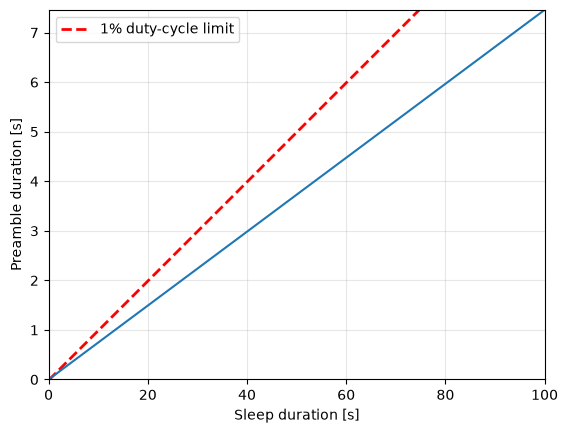

In [ ]:
import sys

sys.path.append(r"C:\Users\Christian\Desktop\lora_energysim_repos\district-heating-multihop-sim")

import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom

from framework.config.models import Mac, Packet

_SF = 6
_BW = 500e3
sym_t = (2**_SF) / _BW
n_candidates = np.arange(1, 3600)

pkt = Packet(payload=bytes(64), created_at=0.0) # 64 B = DR0 in EU868
n_payload = Mac.n_payload_sym(pkt, _SF)
print("Payload symbols", n_payload)


def optimize_symbols(
    n_candidates,
    n_overhearing,
    samp_t,
    sym_t,
    prob_target = 0.99    
):

    low = 6 
    high = int(1e7) # math.ceil(((samp_t * .01) - (n_payload * sym_t)) / sym_t) 
    ans = math.nan

    while low < high:

        mid = (low + high) // 2

        preamb_t = mid * sym_t
        p = min(1.0,  (2 * preamb_t) / (samp_t))

        prob = (
            1 - binom.cdf(n_candidates - 1, n_overhearing, p)
        )

        if prob >= prob_target:
            ans = mid
            high = mid - 1 
        else:
            low = mid + 1
    return ans

cad_intervals = np.linspace(0.01, 100, 100)
toa_data = n_payload * sym_t
duty_cycle = .1
tp_max = duty_cycle * cad_intervals - toa_data

n_preambles = np.array([
    optimize_symbols(n_candidates=3, n_overhearing=40, samp_t=t, sym_t=sym_t, prob_target=.95)
    for t in cad_intervals
])
t_preambles = sym_t * n_preambles

# print("Preamble symbols:", n_preamb)
# print(f"Preamble fraction {(n_preamb * sym_t) / 10.0:.2f}")

plt.plot(cad_intervals, tp_max, "r--", linewidth=2, label="1% duty-cycle limit")
plt.plot(cad_intervals, t_preambles)
plt.xlim(0.0, max(cad_intervals))
plt.ylim(0.0, max(t_preambles))
plt.xlabel("Sleep duration [s]")
plt.ylabel("Preamble duration [s]")
plt.legend()
plt.grid(alpha=.3)



# for i, n_cand in enumerate(n_candidates):
#     for j, interval in enumerate(cad_intervals):
#         n_preamble[i, j] = optimize_symbols(
#             n_overhearing=max(n_candidates),
#             n_candidates=n_cand,
#             samp_t=interval,
#             sym_t=sym_t,
#             prob_target=0.99,
#         )

- Double the CAD interval to reduce required preamble length
- Introduce a correlated phase offset based on UID 
- Find a subband with 10% duty cycle
- Aggregate measurement data

## Scheduling policy

Message identifier **routine** | **leak** 

Application priority with strict priority to leak events. Weighted priority of relayed monitoring traffic according to classical weighted round robin

In [ ]:
from collections import deque
from sys import monitoring
from tkinter import W

from framework.config.models import Packet

relay_q: deque[Packet] = deque()
own_q: deque[Packet] = deque()

# Weighted round-robin schedule for monitoring data 
schedule = {"relay": 3, "own": 1}

idx = 0
def dequeue_packet(pkt: Packet):
    global idx

    expanded = [q for q, w in schedule.items() for _ in range(w)]

    for _ in range(len(expanded)):
        q = expanded[idx]
        idx = (idx + 1) % len(expanded)

        if q == "relay":
            return relay_q.popleft()

        if q == "own":
            return own_q.popleft()

    return None


## Desynchronization of wake up

- Uniform distribution of wakeup is typical assumption
- Overhearing events resynchronize the wakeup instant, but can be accounted for in network simulator by intentionally introducing a random offset

## TX Backoff
- Random backoff from uniform distribution is sufficient to reduce TX collisions, due to
    - Capture efffect
    - Low duty cycle 
    - Not all nodes will relay traffic that causes contention

- Potentially include queue length to prioritize a reduction of congestion at uplink nodes


$$
P = P
$$

In [ ]:
import numpy as np

# Pure ALOHA
N = 40
measure_interval = np.array([10, 100, 1000])
lamb = 1 / measure_interval




